# Notebook 1: Data Preparation

<div dir="rtl" align="right">

يجهّز هذا الملف بيانات Iranian Churn للمشروع: يقرأ الملف الأصلي، ينظّف أسماء الأعمدة، يختار الخصائص العشر، ثم يقسّم البيانات إلى تدريب وتحقق واختبار ويحفظ التقسيم ليستخدمه النموذجان معاً.

</div>

## 1. Import Libraries

<div dir="rtl" align="right">

تستورد الخلية التالية المكتبات المطلوبة لقراءة البيانات ورسمها وتقسيمها.

</div>

In [1]:
# os is used to create folders
import os
# pandas is used to read and handle the data table
import pandas as pd
# matplotlib is used to draw charts
import matplotlib.pyplot as plt
# train_test_split is used to split the data
from sklearn.model_selection import train_test_split

## 2. Set Paths and Constants

<div dir="rtl" align="right">

تحدد الخلية التالية مكان ملف البيانات ومجلدات الحفظ، وتثبّت الرقم العشوائي 433 حتى يعطي الكود نفس التقسيم في كل تشغيل.

</div>

<div dir="rtl" align="right">

تربط الخلية التالية Google Drive مع Colab وتحدد مجلد المشروع `churn_project` في My Drive. جميع المسارات بعد ذلك مبنية على هذا المجلد، لذلك تُحفظ كل النتائج في Drive.

</div>

In [2]:
# tool that connects Google Drive to Colab
from google.colab import drive
# connect Google Drive (Colab asks for permission the first time)
drive.mount("/content/drive")
# project folder inside Google Drive
BASE_FOLDER = "/content/drive/MyDrive/churn_project"
# print the project folder that will be used
print("Project folder:", BASE_FOLDER)

Mounted at /content/drive
Project folder: /content/drive/MyDrive/churn_project


In [3]:
# path of the raw dataset file (kept unchanged)
RAW_FILE = BASE_FOLDER + "/data/Customer Churn.csv"
# folder where the split files will be saved
SPLIT_FOLDER = BASE_FOLDER + "/data/splits"
# folder where charts and tables will be saved
RESULTS_FOLDER = BASE_FOLDER + "/results"
# fixed random seed so the results can be reproduced
SEED = 433
# create the split folder if it does not exist
os.makedirs(SPLIT_FOLDER, exist_ok=True)
# create the results folder if it does not exist
os.makedirs(RESULTS_FOLDER, exist_ok=True)

## 3. Load the Raw Dataset

<div dir="rtl" align="right">

تقرأ الخلية التالية ملف البيانات الأصلي وتعرض عدد الصفوف والأعمدة وأول خمسة صفوف.

</div>

In [4]:
# read the CSV file into a table
df = pd.read_csv(RAW_FILE)
# print the number of rows and columns
print("Rows and columns:", df.shape)
# show the first five rows
df.head()

Rows and columns: (3150, 14)


,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
0,8,0,38,0,4370,71,5,17,3,1,1,30,197.640,0
1,0,0,39,0,318,5,7,4,2,1,2,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,1,1,30,1536.520,0
3,10,0,38,0,4198,66,1,35,1,1,1,15,240.020,0
4,3,0,38,0,2393,58,2,33,1,1,1,15,145.805,0


## 4. Clean the Column Names

<div dir="rtl" align="right">

بعض أسماء الأعمدة في الملف الأصلي تحتوي على مسافات زائدة. تحذف الخلية التالية هذه المسافات حتى تصبح الأسماء موحدة.

</div>

In [5]:
# remove spaces at the start and end of each column name
df.columns = df.columns.str.strip()
# replace repeated spaces inside a name with one space
df.columns = df.columns.str.replace(r"\s+", " ", regex=True)
# print the cleaned column names
print(list(df.columns))

['Call Failure', 'Complains', 'Subscription Length', 'Charge Amount', 'Seconds of Use', 'Frequency of use', 'Frequency of SMS', 'Distinct Called Numbers', 'Age Group', 'Tariff Plan', 'Status', 'Age', 'Customer Value', 'Churn']


## 5. Check Data Types and Missing Values

<div dir="rtl" align="right">

تتحقق الخلية التالية من نوع كل عمود ومن عدد القيم المفقودة، وتتأكد أن عمود الهدف Churn يحتوي على القيمتين 0 و 1 فقط.

</div>

In [6]:
# print the data type of each column
print(df.dtypes)
# print the total number of missing values in the whole table
print("Missing values:", df.isna().sum().sum())
# print the different values found in the target column
print("Target values:", sorted(df["Churn"].unique()))

Call Failure                 int64
Complains                    int64
Subscription Length          int64
Charge Amount                int64
Seconds of Use               int64
Frequency of use             int64
Frequency of SMS             int64
Distinct Called Numbers      int64
Age Group                    int64
Tariff Plan                  int64
Status                       int64
Age                          int64
Customer Value             float64
Churn                        int64
dtype: object
Missing values: 0
Target values: [np.int64(0), np.int64(1)]


## 6. Check the Class Distribution

<div dir="rtl" align="right">

تحسب الخلية التالية عدد العملاء في كل فئة ونسبتهم، وترسمها. يظهر من النتيجة أن البيانات غير متوازنة لأن فئة المغادرين أقل بكثير.

</div>

Churn
0    2655
1     495
Name: count, dtype: int64
Churn
0    84.29
1    15.71
Name: count, dtype: float64


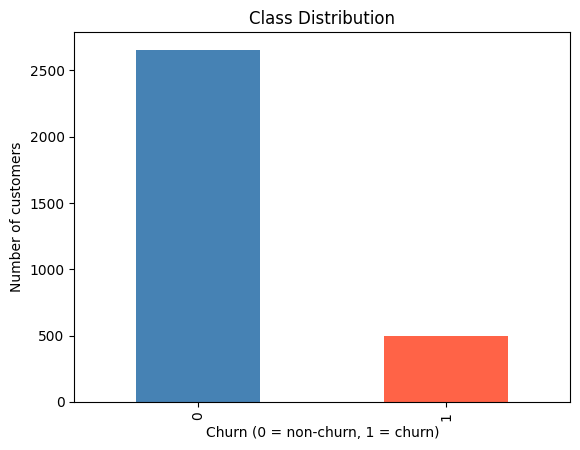

In [7]:
# count the customers in each class
class_counts = df["Churn"].value_counts()
# calculate the percentage of each class
class_percent = (class_counts / len(df) * 100).round(2)
# print the counts
print(class_counts)
# print the percentages
print(class_percent)
# draw the counts as a bar chart
class_counts.plot(kind="bar", color=["steelblue", "tomato"])
# set the chart title
plt.title("Class Distribution")
# set the x-axis label
plt.xlabel("Churn (0 = non-churn, 1 = churn)")
# set the y-axis label
plt.ylabel("Number of customers")
# save the chart as an image
plt.savefig(RESULTS_FOLDER + "/class_distribution.png", dpi=150, bbox_inches="tight")
# display the chart
plt.show()

## 7. Select the Features

<div dir="rtl" align="right">

تختار الخلية التالية الخصائص العشر المستخدمة في المشروع مع عمود الهدف، وتستبعد Age و Age Group و Customer Value. يضاف عمود row_id ليحفظ رقم الصف الأصلي لكل عميل.

</div>

In [8]:
# list of the ten input features used in the project
FEATURES = [
    "Call Failure",
    "Subscription Length",
    "Seconds of Use",
    "Frequency of use",
    "Frequency of SMS",
    "Distinct Called Numbers",
    "Complains",
    "Charge Amount",
    "Tariff Plan",
    "Status",
]
# name of the target column
TARGET = "Churn"
# keep only the selected features and the target
data = df[FEATURES + [TARGET]].copy()
# save the original row number of each customer
data["row_id"] = data.index
# print the new number of rows and columns
print("Rows and columns:", data.shape)

Rows and columns: (3150, 12)


## 8. Summarize the Binary Features

<div dir="rtl" align="right">

تعدّ الخلية التالية العملاء الذين قدموا شكوى، والذين لديهم خطة تعاقدية، والذين حالتهم غير نشطة.

</div>

In [9]:
# count customers who submitted a complaint
print("Customers with a complaint:", (data["Complains"] == 1).sum())
# count customers who use a contractual tariff plan
print("Customers with a contractual plan:", (data["Tariff Plan"] == 2).sum())
# count customers who have a non-active status
print("Customers with non-active status:", (data["Status"] == 2).sum())

Customers with a complaint: 241
Customers with a contractual plan: 245
Customers with non-active status: 782


## 9. Find Repeated Profiles

<div dir="rtl" align="right">

يحتوي الملف على صفوف متكررة. لا تُحذف هذه الصفوف لأن عملاء مختلفين قد يكون لهم نفس الاستخدام. تعطي الخلية التالية رقماً واحداً (profile_id) لكل الصفوف التي لها نفس قيم الخصائص العشر، حتى توضع لاحقاً في نفس الجزء من التقسيم.

</div>

In [10]:
# give the same number to rows that have the same ten feature values
data["profile_id"] = data.groupby(FEATURES).ngroup()
# print the number of rows that repeat an earlier profile
print("Repeated rows:", data.duplicated(FEATURES).sum())
# print the number of different profiles
print("Different profiles:", data["profile_id"].nunique())

Repeated rows: 352
Different profiles: 2798


## 10. Split the Profiles (70% / 15% / 15%)

<div dir="rtl" align="right">

تقسّم الخلية التالية الملفات الشخصية (profiles) وليس الصفوف، حتى لا يظهر نفس الصف المتكرر في جزأين. التقسيم طبقي (stratified) حسب عمود Churn ليحافظ كل جزء على نفس نسبة المغادرين. يتم التقسيم على خطوتين: 70% للتدريب، ثم يُقسم الباقي بالتساوي بين التحقق والاختبار.

</div>

In [11]:
# keep one row for each profile
profiles = data.drop_duplicates("profile_id")
# first split: 70% of the profiles for training, 30% left for later
train_profiles, rest_profiles = train_test_split(
    profiles,
    test_size=0.30,
    stratify=profiles[TARGET],
    random_state=SEED,
)
# second split: divide the remaining 30% equally into validation and test
val_profiles, test_profiles = train_test_split(
    rest_profiles,
    test_size=0.50,
    stratify=rest_profiles[TARGET],
    random_state=SEED,
)

## 11. Assign Every Row to Its Split

<div dir="rtl" align="right">

تكتب الخلية التالية اسم الجزء (train أو validation أو test) لكل صف حسب الملف الشخصي الذي ينتمي إليه، ثم تنشئ جدولاً مستقلاً لكل جزء.

</div>

In [12]:
# start by marking every row as training
data["split"] = "train"
# mark rows whose profile is in the validation profiles
data.loc[data["profile_id"].isin(val_profiles["profile_id"]), "split"] = "validation"
# mark rows whose profile is in the test profiles
data.loc[data["profile_id"].isin(test_profiles["profile_id"]), "split"] = "test"
# create the training table
train = data[data["split"] == "train"]
# create the validation table
val = data[data["split"] == "validation"]
# create the test table
test = data[data["split"] == "test"]

## 12. Check the Split

<div dir="rtl" align="right">

تعرض الخلية التالية عدد الصفوف وعدد كل فئة ونسبة المغادرين في كل جزء، وتتأكد أنه لا يوجد ملف شخصي مشترك بين جزأين.

</div>

In [13]:
# count the rows of each class inside each split
split_summary = pd.crosstab(data["split"], data[TARGET])
# rename the class columns to clear names
split_summary.columns = ["non_churn", "churn"]
# add the total number of rows in each split
split_summary["total"] = split_summary["non_churn"] + split_summary["churn"]
# add the share of each split from the whole dataset
split_summary["share_of_data_%"] = (split_summary["total"] / len(data) * 100).round(2)
# add the churn percentage inside each split
split_summary["churn_%"] = (split_summary["churn"] / split_summary["total"] * 100).round(2)
# show the summary table
print(split_summary)
# count the number of splits that each profile appears in
splits_per_profile = data.groupby("profile_id")["split"].nunique()
# print how many profiles appear in more than one split (must be 0)
print("Profiles in more than one split:", (splits_per_profile > 1).sum())

            non_churn  churn  total  share_of_data_%  churn_%
split                                                        
test              398     69    467            14.83    14.78
train            1855    346   2201            69.87    15.72
validation        402     80    482            15.30    16.60
Profiles in more than one split: 0


## 13. Save the Split

<div dir="rtl" align="right">

تحفظ الخلية التالية الأجزاء الثلاثة في ملفات CSV، وتحفظ ملفاً يحتوي على رقم كل صف والجزء الذي ينتمي إليه. يستخدم النموذجان هذه الملفات نفسها لتكون المقارنة بينهما عادلة.

</div>

In [14]:
# columns that will be saved in each split file
columns_to_save = ["row_id"] + FEATURES + [TARGET]
# save the training data
train[columns_to_save].to_csv(SPLIT_FOLDER + "/train.csv", index=False)
# save the validation data
val[columns_to_save].to_csv(SPLIT_FOLDER + "/validation.csv", index=False)
# save the test data
test[columns_to_save].to_csv(SPLIT_FOLDER + "/test.csv", index=False)
# save the split name of every row
data[["row_id", "split"]].to_csv(SPLIT_FOLDER + "/split_indices.csv", index=False)
# save the summary table of the split
split_summary.to_csv(RESULTS_FOLDER + "/split_summary.csv")
# confirm that the files were saved
print("Split files saved in:", SPLIT_FOLDER)

Split files saved in: /content/drive/MyDrive/churn_project/data/splits


## 14. Record the Library Versions

<div dir="rtl" align="right">

تطبع الخلية التالية إصدار Python والمكتبات المستخدمة وتحفظها في ملف، حتى يمكن إعادة تشغيل المشروع بنفس البيئة.

</div>

In [15]:
# platform is used to read the Python version
import platform
# matplotlib, numpy and sklearn are imported to read their versions
import matplotlib, numpy, sklearn
# collect the version of Python and of each library
versions = {
    "python": platform.python_version(),
    "pandas": pd.__version__,
    "numpy": numpy.__version__,
    "scikit-learn": sklearn.__version__,
    "matplotlib": matplotlib.__version__,
}
# write the versions to a text file in the results folder
with open(RESULTS_FOLDER + "/library_versions.txt", "w") as file:
    # write one library on each line
    for name, version in versions.items():
        file.write(name + "==" + version + "\n")
# print the versions
print(versions)

{'python': '3.13.18', 'pandas': '2.2.3', 'numpy': '2.4.6', 'scikit-learn': '1.6.1', 'matplotlib': '3.10.0'}
